# Étape 2 — Préparation des données

**Objectif :** transformer les données brutes du prof en données prêtes pour
l'entraînement. Trois préparations, chacune avec son résultat :

| Préparation | À quoi elle sert | Résultat |
|---|---|---|
| 1. Le découpage train / validation / test | apprendre, régler et noter sur des images différentes | `data/splits/splits.csv` |
| 2. Le format YOLO | entraîner le détecteur (étape 3) | `data/yolo/` |
| 3. Les vignettes | entraîner le classifieur (étape 4) | `data/crops/` |

Le prof a demandé en séance de faire **la détection avant la classification** :
le découpage et le format YOLO ont servi tout de suite à l'étape 3, et les vignettes
ont été faites juste avant l'étape 4.

**Mode d'emploi :** exécute les cellules une par une (`Maj + Entrée`).
Tout tourne sur le processeur, en deux minutes environ.

## Pour relancer sur Google Colab (facultatif)

En local, la cellule suivante ne fait rien. Sur Colab, avec une carte graphique, c'est
ainsi que nos modèles ont été entraînés :
1. copier le dossier du projet dans le Drive, sous `Mon Drive/projet_avions` ;
2. ouvrir le notebook dans Colab (Exécution > Modifier le type d'exécution > GPU) ;
3. lancer d'abord l'étape 2, qui prépare `data/yolo/` et `data/crops/` sur Colab ;
4. dans les étapes 3 et 4, exécuter la cellule ci-dessous, puis mettre `ENTRAINER = True`.

In [1]:
import os
import sys

SUR_COLAB = "google.colab" in sys.modules
if SUR_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/projet_avions/etapes")
else:
    print("Exécution locale : rien à faire.")

Exécution locale : rien à faire.


## 0. Préparation

In [2]:
import os
import shutil
import xml.etree.ElementTree as ET
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from tqdm import tqdm

# Le notebook se lance depuis le dossier etapes/ : la racine du projet est le dossier parent
RACINE = Path.cwd().parent
RAW_IMAGES_DIR = RACINE / "data" / "raw" / "images"  # 1331 images satellites .jpg
RAW_ANNOTATIONS_DIR = RACINE / "data" / "raw" / "annotations"  # 1331 fichiers .xml (Pascal VOC)
SPLITS_FILE = RACINE / "data" / "splits" / "splits.csv"  # le découpage officiel du projet
YOLO_DIR = RACINE / "data" / "yolo"  # le dataset au format YOLO (partie 2)
CROPS_DIR = RACINE / "data" / "crops"  # les vignettes (partie 3)
assert RAW_IMAGES_DIR.exists(), f"Dataset du prof introuvable : {RAW_IMAGES_DIR}"

# Les 20 types d'avions, dans l'ordre NUMÉRIQUE (un tri alphabétique donnerait A1, A10, A11...
# et les numéros de classe seraient décalés sans erreur visible)
CLASSES = [f"A{i}" for i in range(1, 21)]
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASSES)}

On relit les annotations exactement comme à l'étape 1 : une ligne par avion.

In [3]:
def read_voc_file(xml_path: Path) -> list[dict]:
    """Lit un fichier XML et renvoie une liste de dictionnaires, un par avion annoté."""
    root = ET.parse(xml_path).getroot()
    size = root.find("size")
    image_width = int(size.findtext("width"))
    image_height = int(size.findtext("height"))

    rows = []
    for obj in root.iter("object"):
        box = obj.find("bndbox")
        rows.append(
            {
                "image_id": Path(xml_path).stem,  # "1005" pour "1005.xml"
                "image_width": image_width,
                "image_height": image_height,
                "class_name": obj.findtext("name"),
                "xmin": int(box.findtext("xmin")),
                "ymin": int(box.findtext("ymin")),
                "xmax": int(box.findtext("xmax")),
                "ymax": int(box.findtext("ymax")),
                # "1" si l'avion est coupé par le bord de l'image
                "truncated": obj.findtext("truncated") == "1",
                # "1" si l'annotateur a jugé l'avion difficile à reconnaître
                "difficult": obj.findtext("difficult") == "1",
            }
        )
    return rows


def load_annotations(annotations_dir: Path = RAW_ANNOTATIONS_DIR) -> pd.DataFrame:
    """Charge tous les fichiers XML d'un dossier dans un tableau : une ligne par avion.

    On ajoute aussi des colonnes calculées à partir des coordonnées de la boîte :
    largeur, hauteur, aire, rapport largeur/hauteur et position du centre.
    """
    rows = []
    for xml_path in sorted(Path(annotations_dir).glob("*.xml")):
        rows.extend(read_voc_file(xml_path))
    df = pd.DataFrame(rows)

    df["box_width"] = df["xmax"] - df["xmin"]
    df["box_height"] = df["ymax"] - df["ymin"]
    df["box_area"] = df["box_width"] * df["box_height"]
    df["aspect_ratio"] = df["box_width"] / df["box_height"]  # > 1 : boîte plus large que haute
    # Centre de la boîte, en proportion de l'image (0 = bord gauche/haut, 1 = bord droit/bas)
    df["center_x"] = (df["xmin"] + df["xmax"]) / 2 / df["image_width"]
    df["center_y"] = (df["ymin"] + df["ymax"]) / 2 / df["image_height"]
    return df

In [4]:
objects = load_annotations()
image_ids = sorted(objects["image_id"].unique())
print(f"{len(objects)} avions dans {len(image_ids)} images")

7870 avions dans 1331 images


## 1. Le découpage train / validation / test

### 1.1 Les trois jeux

| Jeu | Part | Rôle |
|---|---|---|
| **train** | 80 % | le modèle apprend dessus |
| **validation** | 10 % | on règle (nombre d'epochs, seuil de confiance) et on compare les modèles |
| **test** | 10 % | la note finale, mesurée **une seule fois**, à la toute fin |

Trois règles :
1. **on découpe par image** : tous les avions d'une image vont dans le même jeu ;
2. **les quasi-doublons restent ensemble** : deux images presque identiques
   dans deux jeux différents, ce serait une **fuite de données** (le modèle serait
   noté sur une image qu'il a pratiquement déjà vue) ;
3. **chaque type d'avion est réparti comme les autres** (stratification) :
   environ 10 % de ses avions en validation et 10 % en test.

### 1.2 Les quasi-doublons

L'analyse (étape 1, partie 2.4) a trouvé des images presque identiques. Pour les
repérer, on calcule une **empreinte visuelle** de chaque image, le *dHash* :
- l'image est réduite à 17 × 16 pixels en niveaux de gris ;
- chaque pixel est comparé à son voisin de droite : 1 s'il est plus clair, 0 sinon ;
- on obtient 256 bits (0 ou 1) qui résument l'image.

Deux images sont des **quasi-doublons** si leurs empreintes diffèrent de 80 bits au plus.
Pendant l'analyse, les vraies paires vues à l'œil étaient à 46, 72 et 73 bits : on garde
une marge, car regrouper par erreur deux images différentes ne coûte presque rien.

On relie ensuite les images proches entre elles, comme dans un graphe : un **groupe**,
c'est un ensemble d'images reliées (une « composante connexe »).

In [5]:
# Distance maximale (en bits sur 256) pour considérer deux images comme quasi identiques
NEAR_DUPLICATE_MAX_DISTANCE = 80


def difference_hash(gray: np.ndarray, hash_size: int = 16) -> np.ndarray:
    """Empreinte (dHash) : image réduite, chaque pixel comparé à son voisin de droite."""
    small = cv2.resize(gray, (hash_size + 1, hash_size), interpolation=cv2.INTER_AREA)
    return (small[:, 1:] > small[:, :-1]).flatten()


def near_duplicate_groups(image_ids, max_distance=NEAR_DUPLICATE_MAX_DISTANCE) -> pd.Series:
    """Donne à chaque image un numéro de groupe : les quasi-doublons ont le même numéro."""
    image_ids = list(image_ids)
    hashes = np.array(
        [
            difference_hash(cv2.imread(str(RAW_IMAGES_DIR / f"{i}.jpg"), cv2.IMREAD_GRAYSCALE))
            for i in image_ids
        ],
        dtype=np.int32,
    )
    # Distance de Hamming entre toutes les paires d'images (nombre de bits différents)
    distances = hashes.shape[1] - (hashes @ hashes.T + (1 - hashes) @ (1 - hashes).T)
    _, labels = connected_components(csr_matrix(distances <= max_distance), directed=False)
    return pd.Series(labels, index=image_ids, name="group")

In [6]:
groups = near_duplicate_groups(image_ids)
group_sizes = groups.value_counts()
print(f"{(group_sizes > 1).sum()} groupes de quasi-doublons (au plus {group_sizes.max()} images)")

15 groupes de quasi-doublons (au plus 3 images)


### 1.3 Le découpage

On utilise `StratifiedGroupKFold` de scikit-learn. Il coupe les données en
**10 paquets** de tailles proches, **sans jamais couper un groupe**, en équilibrant
les types d'avions : le paquet 0 devient le test, le paquet 1 la validation, et les
8 autres le train.

Le résultat dépend d'un tirage au hasard (la **graine**). On essaie donc 50 graines,
et on garde le découpage où **chaque type est le mieux réparti** : celui dont le plus
grand écart à 10 % est le plus petit. Une grosse pénalité écarte les découpages où
un type aurait moins de 3 images en validation ou en test.

In [7]:
SPLIT_NAMES = ["train", "val", "test"]
N_FOLDS = 10  # 10 paquets -> 80 / 10 / 10
MIN_IMAGES_PER_CLASS = 3  # au moins 3 images de chaque type en validation et en test


def split_images(objects: pd.DataFrame, groups: pd.Series, seed: int = 0) -> pd.Series:
    """Renvoie le jeu ("train", "val" ou "test") de chaque image (index = image_id)."""
    splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    # Une ligne par avion : la classe sert à équilibrer, le groupe empêche de couper
    folds = splitter.split(objects, objects["class_name"], objects["image_id"].map(groups))
    split = {}
    for fold, (_, indices) in enumerate(folds):
        name = "test" if fold == 0 else "val" if fold == 1 else "train"
        for image_id in objects["image_id"].iloc[indices]:
            split[image_id] = name
    return pd.Series(split, name="split").sort_index()


def split_report(objects: pd.DataFrame, split: pd.Series):
    """Deux tableaux (une ligne par classe, une colonne par jeu) : avions et images."""
    with_split = objects.assign(split=objects["image_id"].map(split))
    n_objects = pd.crosstab(with_split["class_name"], with_split["split"])
    n_images = with_split.groupby(["class_name", "split"])["image_id"].nunique().unstack()
    shape = {"index": CLASSES, "columns": SPLIT_NAMES, "fill_value": 0}
    return n_objects.reindex(**shape), n_images.reindex(**shape)


def split_score(objects: pd.DataFrame, split: pd.Series) -> float:
    """Plus grand écart à 10 % d'un type en validation ou en test (plus petit = mieux)."""
    n_objects, n_images = split_report(objects, split)
    shares = n_objects.div(n_objects.sum(axis=1), axis=0)  # part de chaque jeu, par type
    gap = (shares[["val", "test"]] - 1 / N_FOLDS).abs().to_numpy().max()
    too_few_images = (n_images[["val", "test"]] < MIN_IMAGES_PER_CLASS).to_numpy().any()
    return gap + (1.0 if too_few_images else 0.0)


def best_split(objects: pd.DataFrame, groups: pd.Series, seeds=range(50)):
    """Essaie plusieurs graines et renvoie (meilleur découpage, sa graine, son score)."""
    candidates = ((split_images(objects, groups, seed), seed) for seed in seeds)
    scored = ((split, seed, split_score(objects, split)) for split, seed in candidates)
    return min(scored, key=lambda result: result[2])

In [8]:
split, seed, score = best_split(objects, groups)
print(f"Graine retenue : {seed}")
print(f"Plus grand écart à 10 % pour un type d'avion : {100 * score:.1f} points")

Graine retenue : 19
Plus grand écart à 10 % pour un type d'avion : 1.2 points


### 1.4 Vérification et enregistrement

Le découpage officiel du projet est déjà enregistré dans `data/splits/splits.csv`,
et tous les modèles ont été entraînés avec lui. On vérifie que le calcul redonne
**exactement** le même découpage. On ne l'écrase jamais : le fichier n'est écrit que
s'il n'existe pas encore.

In [9]:
table = split.to_frame().join(groups)
table.index.name = "image_id"
if SPLITS_FILE.exists():
    officiel = pd.read_csv(SPLITS_FILE, dtype={"image_id": str}).set_index("image_id")
    identique = officiel["split"].sort_index().equals(table["split"].sort_index())
    print("Identique au découpage officiel du projet :", identique)
    assert identique
else:
    SPLITS_FILE.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(SPLITS_FILE)
    print("Découpage écrit :", SPLITS_FILE)

n_objects, n_images = split_report(objects, split)
resume = pd.DataFrame({"images": split.value_counts(), "avions": n_objects.sum()}).reindex(
    SPLIT_NAMES
)
resume["part des images"] = (resume["images"] / resume["images"].sum()).map("{:.0%}".format)
resume

Identique au découpage officiel du projet : True


,images,avions,part des images
split,,,
train,1070,6295,80%
val,130,787,10%
test,131,788,10%


La stratification se voit sur ce graphique : pour chaque type d'avion, la part de ses
avions qui tombe en validation et en test reste proche des 10 % visés.

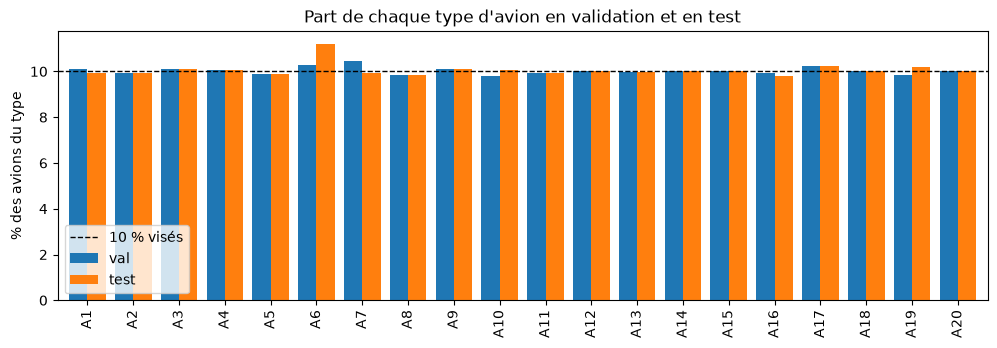

In [10]:
parts = n_objects.div(n_objects.sum(axis=1), axis=0)[["val", "test"]] * 100
ax = parts.plot.bar(figsize=(12, 3.5), width=0.8)
ax.axhline(10, color="black", linestyle="--", linewidth=1, label="10 % visés")
ax.set_ylabel("% des avions du type")
ax.set_xlabel("")
ax.set_title("Part de chaque type d'avion en validation et en test")
ax.legend()
plt.show()

## 2. Le format YOLO (pour le détecteur)

YOLO n'utilise pas les fichiers XML : il veut **un fichier texte par image**, avec une
ligne par avion :

    classe  x_centre  y_centre  largeur  hauteur

- `classe` : numéro de 0 à 19 (A1 -> 0, ..., A20 -> 19) ;
- les 4 nombres sont **divisés par la taille de l'image** : ils vont de 0 à 1, et
  restent donc valables si YOLO redimensionne l'image.

Exemple avec la première image, `1005.jpg` (800 × 800 px), qui contient un A2 et un A10 :

In [11]:
def voc_to_yolo_lines(boxes: pd.DataFrame) -> list[str]:
    """Convertit les avions d'UNE image (une ligne par avion) en lignes au format YOLO."""
    lines = []
    for box in boxes.itertuples():
        x_center = (box.xmin + box.xmax) / 2 / box.image_width
        y_center = (box.ymin + box.ymax) / 2 / box.image_height
        width = (box.xmax - box.xmin) / box.image_width
        height = (box.ymax - box.ymin) / box.image_height
        class_index = CLASS_TO_INDEX[box.class_name]
        lines.append(f"{class_index} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}")
    return lines


exemple = objects[objects["image_id"] == "1005"]
display(exemple[["class_name", "xmin", "ymin", "xmax", "ymax"]])
print("\n".join(voc_to_yolo_lines(exemple)))

,class_name,xmin,ymin,xmax,ymax
0,A2,275,22,385,149
1,A10,262,470,404,596


1 0.412500 0.106875 0.137500 0.158750
9 0.416250 0.666250 0.177500 0.157500


On écrit ensuite tout le dataset dans `data/yolo/`, avec l'organisation attendue par
Ultralytics : un dossier `images/` et un dossier `labels/` jumeaux, coupés en
train / val / test, plus un fichier `dataset.yaml` qui décrit le tout.

Les images ne sont pas recopiées : on crée des **liens durs**, deux noms pour le même
fichier sur le disque. Ça ne prend aucune place en plus.

In [12]:
def link_or_copy(source: Path, destination: Path) -> None:
    """Crée un « lien dur » vers l'image (aucune place disque en plus), sinon la copie."""
    try:
        os.link(source, destination)
    except OSError:
        shutil.copy2(source, destination)


def build_yolo_dataset(objects: pd.DataFrame, split: pd.Series, out_dir: Path = YOLO_DIR) -> Path:
    """Construit le dataset YOLO (images, étiquettes, fichier YAML), renvoie le chemin du YAML.

    Le dossier est entièrement régénéré à chaque appel (il ne contient que des fichiers
    dérivés des données du prof).
    """
    shutil.rmtree(out_dir, ignore_errors=True)
    for name in SPLIT_NAMES:
        (out_dir / "images" / name).mkdir(parents=True)
        (out_dir / "labels" / name).mkdir(parents=True)

    for image_id, boxes in objects.groupby("image_id"):
        name = split[image_id]
        link_or_copy(
            RAW_IMAGES_DIR / f"{image_id}.jpg", out_dir / "images" / name / f"{image_id}.jpg"
        )
        labels = "\n".join(voc_to_yolo_lines(boxes)) + "\n"
        (out_dir / "labels" / name / f"{image_id}.txt").write_text(labels)

    # Fichier de description du dataset, lu par Ultralytics
    description = {
        "path": str(out_dir.resolve()),
        "train": "images/train",
        "val": "images/val",
        "test": "images/test",
        "names": dict(enumerate(CLASSES)),
    }
    yaml_path = out_dir / "dataset.yaml"
    yaml_path.write_text(yaml.safe_dump(description, sort_keys=False), encoding="utf-8")
    return yaml_path


yaml_path = build_yolo_dataset(objects, split)
print("Dataset YOLO écrit :", yaml_path.parent)
for name in SPLIT_NAMES:
    n_labels = len(list((YOLO_DIR / "labels" / name).glob("*.txt")))
    print(f"  {name:5s} : {n_labels:4d} images et fichiers d'étiquettes")

Dataset YOLO écrit : C:\Users\deror\Desktop\projet_ia\data\yolo
  train : 1070 images et fichiers d'étiquettes
  val   :  130 images et fichiers d'étiquettes
  test  :  131 images et fichiers d'étiquettes


## 3. Les vignettes (pour le classifieur)

Le classifieur ne regarde pas l'image entière, mais une **vignette** : un carré
découpé autour de chaque avion, à partir de sa boîte dans le fichier XML.

| Choix | Pourquoi |
|---|---|
| un carré de **2 × le plus grand côté** de la boîte, centré sur l'avion | on garde du contexte, et assez de marge pour faire tourner la vignette (data augmentation, étape 4) sans faire apparaître de coins vides |
| du **gris neutre** quand le carré dépasse de l'image | pour les avions au bord |
| ramené à **256 × 256 px** | un réseau veut des images toutes de la même taille ; l'avion y mesure alors environ 128 px, à peu près sa taille d'origine (médiane : 111 px, étape 1) |

Les boîtes du XML n'ont pas toutes la même taille (de 38 à 566 px de côté) : les carrés
découpés non plus. C'est le redimensionnement final qui les met tous à 256 × 256 px.

**Point important :** la même fonction `make_crop` sert aussi dans l'application finale
(étape 5), avec les boîtes trouvées par le détecteur. Le classifieur voit ainsi à
l'usage le même genre de vignettes qu'à l'entraînement.

In [13]:
CROP_SCALE = 2.0  # côté du carré / plus grand côté de la boîte
CROP_SIZE = 256  # taille des vignettes enregistrées, en pixels
PAD_VALUE = 128  # gris neutre pour compléter au-delà du bord de l'image


def make_crop(image: np.ndarray, box: tuple[float, float, float, float]) -> np.ndarray:
    """Découpe un carré centré sur la boîte (xmin, ymin, xmax, ymax) et le redimensionne."""
    xmin, ymin, xmax, ymax = box
    center_x, center_y = (xmin + xmax) / 2, (ymin + ymax) / 2
    half_side = CROP_SCALE * max(xmax - xmin, ymax - ymin) / 2
    x0, y0 = round(center_x - half_side), round(center_y - half_side)
    x1, y1 = round(center_x + half_side), round(center_y + half_side)

    # Si le carré sort de l'image, on ajoute une bordure grise tout autour de l'image
    height, width = image.shape[:2]
    pad = max(0, -x0, -y0, x1 - width, y1 - height)
    if pad:
        image = cv2.copyMakeBorder(
            image, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=(PAD_VALUE,) * 3
        )
    square = image[y0 + pad : y1 + pad, x0 + pad : x1 + pad]

    # INTER_AREA pour réduire (net, sans crénelage), INTER_LINEAR pour agrandir
    shrinking = square.shape[0] > CROP_SIZE
    interpolation = cv2.INTER_AREA if shrinking else cv2.INTER_LINEAR
    return cv2.resize(square, (CROP_SIZE, CROP_SIZE), interpolation=interpolation)

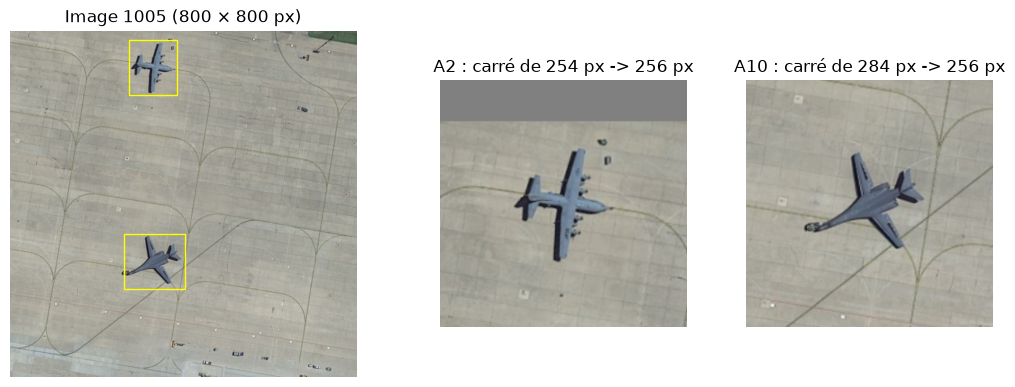

In [14]:
# Exemple : l'image 1005 et les vignettes de ses deux avions
image = cv2.imread(str(RAW_IMAGES_DIR / "1005.jpg"))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.6, 1, 1]})
axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Image 1005 (800 × 800 px)")
for ax, box in zip(axes[1:], exemple.itertuples(), strict=True):
    cote = max(box.box_width, box.box_height)
    axes[0].add_patch(
        plt.Rectangle(
            (box.xmin, box.ymin), box.box_width, box.box_height, fill=False, color="yellow"
        )
    )
    crop = make_crop(image, (box.xmin, box.ymin, box.xmax, box.ymax))
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{box.class_name} : carré de {2 * cote} px -> 256 px")
for ax in axes:
    ax.axis("off")
plt.show()

On découpe maintenant **toutes** les vignettes : une par avion annoté, rangée dans le
dossier de son jeu (`data/crops/train/`, `val/`, `test/`). Le fichier `index.csv`
garde une ligne par vignette : son fichier, son image d'origine, son jeu et son type.

In [15]:
shutil.rmtree(CROPS_DIR, ignore_errors=True)  # dossier entièrement régénéré
for name in SPLIT_NAMES:
    (CROPS_DIR / name).mkdir(parents=True)

rows = []
for image_id, boxes in tqdm(objects.groupby("image_id"), desc="Vignettes"):
    # Chaque image n'est lue qu'une seule fois, pour tous ses avions
    image = cv2.imread(str(RAW_IMAGES_DIR / f"{image_id}.jpg"))
    split_name = split[image_id]
    for number, box in enumerate(boxes.itertuples()):
        crop = make_crop(image, (box.xmin, box.ymin, box.xmax, box.ymax))
        crop_path = f"{split_name}/{image_id}_{number}.jpg"
        cv2.imwrite(str(CROPS_DIR / crop_path), crop, [cv2.IMWRITE_JPEG_QUALITY, 95])
        rows.append(
            {
                "crop_path": crop_path,
                "image_id": image_id,
                "split": split_name,
                "class_name": box.class_name,
                "label": CLASS_TO_INDEX[box.class_name],
                "box_width": box.box_width,
                "box_height": box.box_height,
                "truncated": box.truncated,
            }
        )

index = pd.DataFrame(rows)
index.to_csv(CROPS_DIR / "index.csv", index=False)
print(f"{len(index)} vignettes écrites dans {CROPS_DIR}")
index["split"].value_counts().reindex(SPLIT_NAMES)

Vignettes: 100%|██████████| 1331/1331 [00:16<00:00, 79.81it/s]

7870 vignettes écrites dans C:\Users\deror\Desktop\projet_ia\data\crops


split
train    6295
val       787
test      788
Name: count, dtype: int64

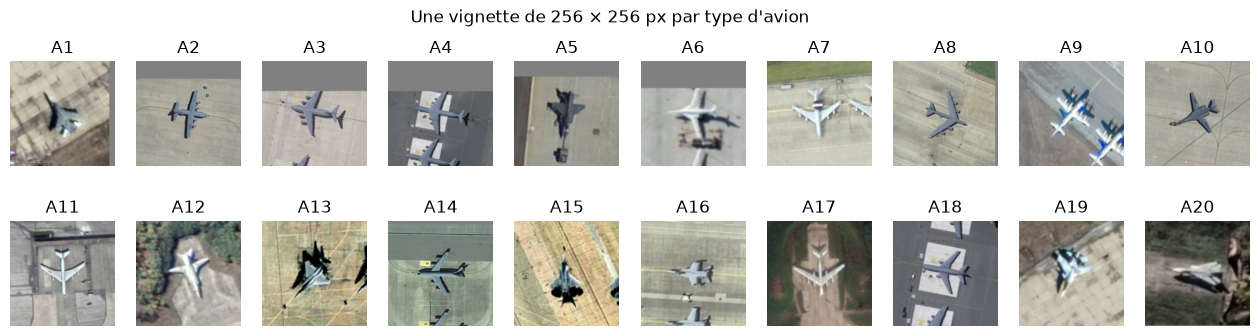

In [16]:
# Une vignette d'entraînement par type d'avion
fig, axes = plt.subplots(2, 10, figsize=(16, 3.8))
for ax, classe in zip(axes.flat, CLASSES, strict=True):
    ligne = index[(index["split"] == "train") & (index["class_name"] == classe)].iloc[0]
    ax.imshow(cv2.cvtColor(cv2.imread(str(CROPS_DIR / ligne.crop_path)), cv2.COLOR_BGR2RGB))
    ax.set_title(classe)
    ax.axis("off")
plt.suptitle("Une vignette de 256 × 256 px par type d'avion")
plt.show()

## 4. Ce qu'il faut retenir

- **Trois jeux** : train pour apprendre, validation pour régler, test pour la note
  finale, mesurée une seule fois.
- **Pas de fuite de données** : on découpe par image, et les quasi-doublons restent
  dans le même jeu.
- **Stratification** : chaque type d'avion a environ 10 % de ses avions en
  validation et 10 % en test.
- **Deux formats pour deux modèles** : le format YOLO pour le détecteur, et les
  vignettes de 256 × 256 px pour le classifieur.
- **Une seule fonction de découpe**, `make_crop`, pour l'entraînement et pour
  l'application.

Suite : **étape 3, la détection**.